**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión**

---

# **Clase 19 - Simulación de datos y muestreo**

*Fabricar datos, elegir bien una muestra y simular el futuro de un negocio*

---

## Complemento

Este notebook va **en paralelo** con la presentación **`Simulacion_y_muestreo.html`** (carpeta `PPT's/` del repo; descargala y abrila con el navegador).
Cada parte de acá dice a qué slide corresponde: en la presentación está la idea, y acá **cómo se hace en Python**.

## ¿Qué vamos a hacer en esta clase?

**Simular** es fabricar datos con la computadora. Vamos a hacer cuatro cosas, siempre con código cortito y comentado línea por línea (lo que va después de un `#` es un comentario: Python no lo ejecuta, es para nosotros):

| Parte | Qué hacemos | Slides |
|---|---|---|
| **A** | Tirar dados con la computadora (y entender la *semilla*) | 4 |
| **B** | Inventar una base de 100.000 clientes, y ver para qué sirve en Machine Learning | 5 a 7 |
| **C** | Hacer encuestas y ver cuánto se equivocan | 8 a 12 |
| **D** | Simular para decidir: las medialunas y el horno | 13 a 17 |

> **La idea de la clase:** con la computadora podemos probar miles de veces algo que en la vida real pasa una sola vez.

In [1]:
# Las tres librerías de siempre
import numpy as np                  # números y cuentas (y el generador de números al azar)
import pandas as pd                 # tablas (DataFrames)
import matplotlib.pyplot as plt     # gráficos

# Los colores de la cátedra para los gráficos
AZUL, NARANJA = "#243b5e", "#e07b39"

---
# A. Tirar dados con la computadora (slide 4)

Para fabricar números al azar usamos un **generador**. Se crea con `np.random.default_rng(semilla)`.

La **semilla** es el número desde el que arranca. **Misma semilla, mismos números**: así cualquiera puede repetir nuestro análisis y obtener lo mismo.

In [2]:
# Creamos el generador de números al azar, con la semilla 42
rng = np.random.default_rng(42)

# Pedimos 10.000 números enteros entre 1 y 6 (el 7 no se incluye): es como tirar un dado 10.000 veces
tiradas = rng.integers(1, 7, size=10_000)

# Mostramos solo las primeras diez ([:10] = "del principio hasta la posición 10")
print("Las primeras diez tiradas:", tiradas[:10])

Las primeras diez tiradas: [1 5 4 3 3 6 1 5 2 1]


Si volvemos a crear el generador con la **misma semilla**, salen **exactamente los mismos** dados. Probá cambiar el 42 por otro número y volver a correr.

In [3]:
# Volvemos a crear el generador con la MISMA semilla...
rng = np.random.default_rng(42)
tiradas = rng.integers(1, 7, size=10_000)

# ...y salen exactamente los mismos dados que arriba
print("Las primeras diez tiradas:", tiradas[:10])

Las primeras diez tiradas: [1 5 4 3 3 6 1 5 2 1]


¿Sale cada cara una de cada seis veces? Contamos cuántas veces salió cada una:

1    0.168
2    0.172
3    0.166
4    0.167
5    0.164
6    0.162
Name: proportion, dtype: float64


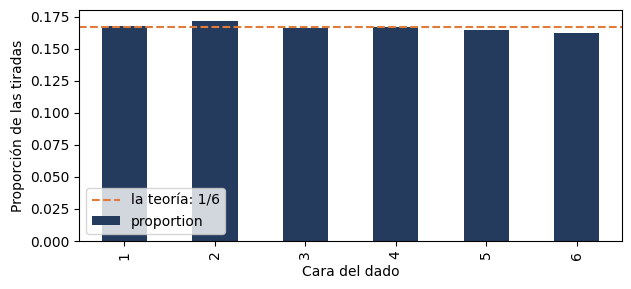

In [4]:
# Pasamos las tiradas a una Serie de pandas y contamos cuántas veces salió cada cara.
# normalize=True da la PROPORCIÓN en vez de la cantidad; sort_index() las ordena de 1 a 6.
conteo = pd.Series(tiradas).value_counts(normalize=True).sort_index()
print(conteo.round(3))

# Gráfico de barras: una barra por cara
conteo.plot.bar(color=AZUL, figsize=(7, 3))
plt.axhline(1 / 6, color=NARANJA, ls="--", label="la teoría: 1/6")   # línea horizontal en 1/6
plt.xlabel("Cara del dado")
plt.ylabel("Proporción de las tiradas")
plt.legend()
plt.show()

Todas las caras quedan muy cerca de 1/6 (0,167). Tiramos 10.000 dados en un segundo: **eso es simular**.

---
# B. Una base de datos inventada: 100.000 clientes (slides 5 y 6)

Vamos a inventar los clientes de una empresa. Cada cliente tiene:
- un **segmento**: Básico (60%), Medio (30%) o Premium (10%);
- un **canal**: Online (35%) o Sucursal (65%);
- un **gasto mensual**.

`rng.choice` elige al azar entre opciones, con las probabilidades que le digamos en `p`:

In [5]:
rng = np.random.default_rng(2026)     # nuevo generador, con otra semilla
N = 100_000                           # cantidad de clientes que vamos a inventar

# Armamos la tabla. Cada columna se llena eligiendo al azar N veces entre las opciones,
# con las probabilidades de p (tienen que sumar 1)
clientes = pd.DataFrame({
    "segmento": rng.choice(["Básico", "Medio", "Premium"], size=N, p=[0.60, 0.30, 0.10]),
    "canal":    rng.choice(["Online", "Sucursal"], size=N, p=[0.35, 0.65]),
})

clientes.head()     # las primeras cinco filas

,segmento,canal
0,Básico,Online
1,Medio,Online
2,Básico,Online
3,Básico,Sucursal
4,Básico,Sucursal


Ahora el **gasto**, en tres pasos fáciles:

In [6]:
# Paso 1: cada cliente arranca con el gasto típico de su segmento.
# .map() reemplaza cada segmento por el número que le corresponde en el diccionario
gasto_tipico = {"Básico": 60_000, "Medio": 110_000, "Premium": 250_000}
clientes["gasto"] = clientes["segmento"].map(gasto_tipico)

# Paso 2: le sumamos variedad al azar. rng.uniform(0.5, 1.5) da un número entre 0,5 y 1,5:
# multiplicar por eso hace que cada cliente gaste entre un 50% menos y un 50% más que el típico
clientes["gasto"] = clientes["gasto"] * rng.uniform(0.5, 1.5, size=N)

# Paso 3: los clientes de Online gastan un 30% más.
# es_online vale True en las filas de Online; .loc[es_online, "gasto"] toma solo esas filas
es_online = clientes["canal"] == "Online"
clientes.loc[es_online, "gasto"] = clientes.loc[es_online, "gasto"] * 1.3

# Redondeamos a pesos enteros y miramos cómo quedó
clientes["gasto"] = clientes["gasto"].round()
clientes.head()

,segmento,canal,gasto
0,Básico,Online,91462.0
1,Medio,Online,109257.0
2,Básico,Online,55342.0
3,Básico,Sucursal,72651.0
4,Básico,Sucursal,48328.0


### La verdad (que en la vida real nunca conocemos)

Como la población la inventamos nosotros, podemos calcular el **gasto promedio verdadero**. Es el número que después vamos a tratar de adivinar con encuestas.

In [7]:
# El promedio de TODOS los clientes: la verdad que una encuesta quiere adivinar
gasto_verdadero = clientes["gasto"].mean()
print("Gasto promedio verdadero:", round(gasto_verdadero))

# Gasto promedio de cada segmento: agrupamos por segmento y promediamos el gasto
clientes.groupby("segmento")["gasto"].mean().round()

Gasto promedio verdadero: 103907


segmento
Básico      66233.0
Medio      121479.0
Premium    278572.0
Name: gasto, dtype: float64

El gasto promedio verdadero es **\$ 103.907**. Fijate que los Premium son pocos pero gastan muchísimo más que el resto: eso va a importar en la parte C.

---
## Esto lo van a volver a ver en Machine Learning (slide 7)

Más adelante en la carrera van a ver **Machine Learning**: modelos que *aprenden* de los datos para predecir (si un cliente se va a ir, cuánto va a gastar, si un crédito se va a pagar). Lo de hoy aparece ahí todo el tiempo:

1. **Probar un modelo con datos inventados.** Si nosotros fabricamos los datos, sabemos qué patrón pusimos (por ejemplo, "los de Online gastan un 30% más"). Si el modelo no lo encuentra, algo anda mal. Por eso las librerías de Machine Learning traen funciones para fabricar datos de práctica.
2. **Separar los datos al azar, con semilla.** Un modelo se entrena con una parte de los datos (**entrenamiento**) y se evalúa con otra que nunca vio (**prueba**). Esa separación es un **muestreo al azar** con `random_state=42`, y muchas veces **estratificado**: lo mismo que vamos a hacer hoy.
3. **Datos sintéticos.** Cuando hay pocos datos, o son privados (de clientes, de pacientes), se fabrican datos parecidos para entrenar sin exponer a nadie.

Así se separa una base en entrenamiento y prueba con lo que ya saben de pandas:

In [8]:
# frac=0.8: elegimos al azar el 80% de las filas. random_state=42 es la semilla de pandas
entrenamiento = clientes.sample(frac=0.8, random_state=42)     # con esto aprendería el modelo

# .drop() saca filas: le sacamos a la base las que ya fueron a entrenamiento, y queda el 20% restante
prueba = clientes.drop(entrenamiento.index)                   # con esto se evalúa el modelo

print(len(entrenamiento), "clientes para entrenar")           # len() cuenta las filas
print(len(prueba), "clientes para probar")

80000 clientes para entrenar
20000 clientes para probar


---
# C. Muestreo: ¿cuánto le podemos creer a una encuesta?

### Una encuesta de 100 clientes (slide 8)

Supongamos que no podemos mirar a los 100.000 clientes y encuestamos a **100 al azar**. Es lo que hacíamos en la clase 06 con `.sample()`:

In [9]:
# Elegimos 100 clientes al azar (random_state=1 es la semilla: así siempre salen los mismos 100)
muestra = clientes.sample(100, random_state=1)

# Comparamos el promedio de la encuesta con la verdad
print("La encuesta dice:", round(muestra["gasto"].mean()))
print("La verdad es    :", round(gasto_verdadero))

La encuesta dice: 97891
La verdad es    : 103907


Se acerca, pero no da justo: mirar solo una parte siempre tiene algo de error. **No es un error de cuentas**: es lo que pasa por no mirar a todos.

### ¿Y si encuestamos a más gente? (slide 9)

Hacemos encuestas cada vez más grandes y miramos cuánto se equivoca cada una:

In [10]:
# El for repite el bloque de abajo una vez por cada tamaño de la lista
for n in [10, 50, 100, 500, 1_000, 5_000, 10_000]:
    muestra = clientes.sample(n, random_state=1)                 # encuesta de n clientes al azar
    error = abs(muestra["gasto"].mean() - gasto_verdadero)      # abs(): la distancia, sin importar si es para arriba o para abajo
    print(f"Encuesta de {n} clientes: se equivoca por $ {round(error)}")

Encuesta de 10 clientes: se equivoca por $ 10213
Encuesta de 50 clientes: se equivoca por $ 6791
Encuesta de 100 clientes: se equivoca por $ 6016
Encuesta de 500 clientes: se equivoca por $ 785
Encuesta de 1000 clientes: se equivoca por $ 232
Encuesta de 5000 clientes: se equivoca por $ 218
Encuesta de 10000 clientes: se equivoca por $ 371


Con pocos clientes el error es grande; con más gente **se achica**. Pero pasar de 1.000 a 10.000 casi no mejora nada, y cuesta diez veces más.
Por eso las encuestas serias de un país entero usan **unas 1.000 personas**... **siempre que se elijan al azar**.

### ¿Importa a quién le preguntamos? (slides 10 y 11)

Comparamos tres formas de elegir a 200 clientes:

| Forma | Cómo se elige | En pandas |
|---|---|---|
| **Aleatoria** | cualquiera de los 100.000, al azar | `clientes.sample(200)` |
| **Estratificada** | al azar *dentro de cada segmento*, respetando cuántos hay | `clientes.groupby("segmento").sample(frac=0.002)` |
| **Por conveniencia** | solo los fáciles de encontrar: los de Online (una encuesta por la app) | `online.sample(200)` |

Una sola encuesta puede salir bien o mal de casualidad. Por eso **repetimos cada forma 200 veces** (cada vez con otra semilla, `random_state=i`) y guardamos el resultado:

In [11]:
# Los clientes de Online: son los únicos que contestan una encuesta por la app
online = clientes[clientes["canal"] == "Online"]

# Tres listas vacías: ahí vamos guardando lo que da cada encuesta
aleatoria, estratificada, conveniencia = [], [], []

# Repetimos 200 veces. En cada vuelta, i vale 0, 1, 2, ... 199 y lo usamos como semilla
for i in range(200):
    # Aleatoria: 200 clientes al azar de toda la base
    aleatoria.append(clientes.sample(200, random_state=i)["gasto"].mean())
    # Estratificada: el 0,2% de CADA segmento (120 Básicos, 60 Medios y 20 Premium = 200)
    estratificada.append(clientes.groupby("segmento").sample(frac=0.002, random_state=i)["gasto"].mean())
    # Por conveniencia: 200 clientes, pero solo de los de Online
    conveniencia.append(online.sample(200, random_state=i)["gasto"].mean())
    # .append() agrega el promedio de la encuesta al final de la lista

# Juntamos las tres listas en una tabla: una columna por forma, una fila por vuelta
encuestas = pd.DataFrame({"Aleatoria": aleatoria, "Estratificada": estratificada, "Por conveniencia": conveniencia})
encuestas.head()

,Aleatoria,Estratificada,Por conveniencia
0,98363.550,106710.730,112302.035
1,99634.950,111595.865,130187.690
2,105496.435,101290.405,127347.140
3,104870.035,103044.880,118872.270
4,107327.755,101517.960,105685.240


Cada fila es una vuelta: lo que dio cada forma de encuestar. Lo vemos en un gráfico:

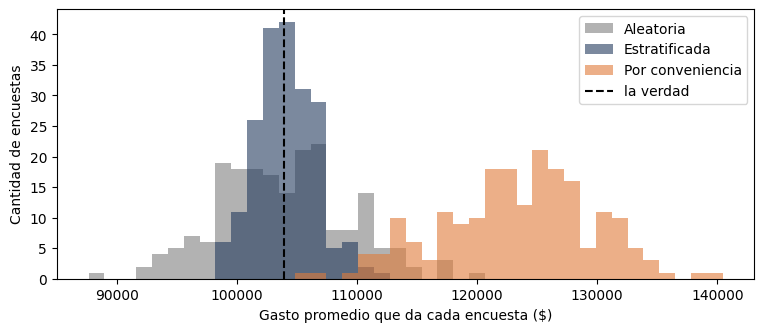

In [12]:
# Un histograma por columna, superpuestos (alpha=0.6 los hace un poco transparentes)
encuestas.plot.hist(bins=40, alpha=0.6, color=["gray", AZUL, NARANJA], figsize=(9, 3.5))

# Línea vertical en el promedio verdadero, para comparar
plt.axvline(gasto_verdadero, color="black", ls="--", label="la verdad")
plt.xlabel("Gasto promedio que da cada encuesta ($)")
plt.ylabel("Cantidad de encuestas")
plt.legend()
plt.show()

Y medimos **cuánto se equivoca, en promedio, cada forma** (sin importar si se pasa para arriba o para abajo):

In [13]:
# A cada encuesta le restamos la verdad y le sacamos el signo con .abs(): queda la distancia
errores = (encuestas - gasto_verdadero).abs()

# Promedio de esas distancias, para cada forma de encuestar
errores.mean().round()

Aleatoria            4429.0
Estratificada        2023.0
Por conveniencia    19342.0
dtype: float64

- **Aleatoria:** las encuestas caen alrededor de la verdad, a veces arriba y a veces abajo. Cada una se equivoca por unos **\$ 4.429**.
- **Estratificada:** también alrededor de la verdad, y **más juntas** (**\$ 2.023**). Al asegurar la cantidad justa de Premium, ninguna encuesta queda con demasiados o con muy pocos clientes que gastan mucho.
- **Por conveniencia:** **todas** se pasan para arriba, por unos **\$ 19.342**, porque los clientes de Online gastan más. Eso es un **sesgo**: un error que va siempre para el mismo lado.

### ¿Y si mandamos la encuesta por la app a mucha más gente? (slide 12)

In [14]:
# Encuestas por la app cada vez más grandes (siempre solo clientes de Online)
for n in [200, 2_000, 20_000]:
    muestra = online.sample(n, random_state=1)
    error = muestra["gasto"].mean() - gasto_verdadero      # sin abs(): queremos ver para qué lado se equivoca
    print(f"Encuesta por la app a {n} clientes: se pasa por $ {round(error)}")

Encuesta por la app a 200 clientes: se pasa por $ 26281
Encuesta por la app a 2000 clientes: se pasa por $ 22272
Encuesta por la app a 20000 clientes: se pasa por $ 19123


> **El sesgo no se arregla con más datos.** Con 20.000 respuestas el error sigue ahí: solo estamos más seguros de un número equivocado.
> Antes de preguntar **cuántos** datos hay, preguntá **quiénes** son.

---
# D. Simular para decidir: Monte Carlo (slide 13)

En un negocio muchas cosas no se saben de antemano: cuánto se va a vender, cuánto van a rendir los flujos de un proyecto.
La **simulación de Monte Carlo** consiste en **simular miles de días o de futuros posibles** y elegir la decisión que mejor funciona en todos.

### Caso 1: ¿cuántas medialunas hornear? (slides 14 y 15)

Una panadería vende cada medialuna a **\$500** y hacerla le cuesta **\$200**. Lo que sobra al final del día se tira.
La demanda cambia todos los días: en promedio piden **120**, a veces más y a veces menos.

**Paso 1:** simulamos la demanda de 1.000 días. Usamos `rng.normal(promedio, desvío)`: la campana de siempre, centrada en 120.

In [15]:
rng = np.random.default_rng(8)

# 1.000 números de una campana con promedio 120 y desvío 15, redondeados a medialunas enteras.
# Cada número es lo que piden en un día: la mayoría de los días, entre 90 y 150
demanda = rng.normal(120, 15, size=1000).round()

print("Los primeros 10 días piden:", demanda[:10])
print("Promedio de los 1.000 días:", demanda.mean())

Los primeros 10 días piden: [ 94. 100. 100. 115.  85. 117. 106. 133. 134. 141.]
Promedio de los 1.000 días: 119.566


**Paso 2:** una función que calcula la ganancia promedio si horneamos cierta cantidad.
`np.minimum` elige, día por día, el menor de dos números: se venden las que piden, pero **nunca más de las que se hornearon**.

In [16]:
PRECIO = 500     # lo que cobra por cada medialuna vendida
COSTO = 200      # lo que le cuesta hacer cada medialuna (se venda o no)

# def crea una función: le pasamos cuántas hornear y nos devuelve la ganancia promedio
def ganancia_promedio(hornear):
    vendidas = np.minimum(demanda, hornear)            # cada día se vende lo que piden, con el tope de lo horneado
    ganancia = vendidas * PRECIO - hornear * COSTO     # se cobran las vendidas y se pagan TODAS las horneadas
    return ganancia.mean()                             # promedio de los 1.000 días

# Probamos la función con una cantidad
print("Horneando 120 se gana, en promedio,", round(ganancia_promedio(120)), "por día")

Horneando 120 se gana, en promedio, 32866 por día


**Paso 3:** probamos todas las cantidades entre 90 y 160, y nos quedamos con la mejor. `.apply` aplica la función a cada fila:

In [17]:
# Una tabla con una fila por cada cantidad posible: 90, 91, 92, ... 160
resultados = pd.DataFrame({"hornear": range(90, 161)})

# .apply() corre ganancia_promedio para cada fila y guarda el resultado en una columna nueva
resultados["ganancia promedio"] = resultados["hornear"].apply(ganancia_promedio)

# Ordenamos de mayor a menor ganancia y mostramos las tres mejores
resultados.sort_values("ganancia promedio", ascending=False).head(3)

,hornear,ganancia promedio
33,123,32944.0
34,124,32943.0
32,122,32930.0


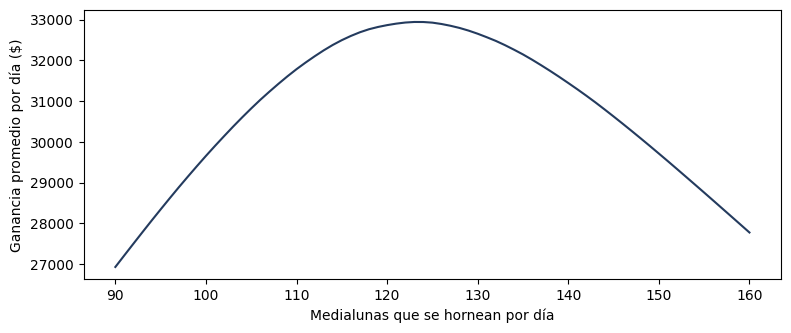

In [18]:
# Gráfico de línea: en el eje x la cantidad horneada, en el eje y la ganancia promedio
resultados.plot(x="hornear", y="ganancia promedio", color=AZUL, legend=False, figsize=(9, 3.5))
plt.xlabel("Medialunas que se hornean por día")
plt.ylabel("Ganancia promedio por día ($)")
plt.show()

Conviene hornear **123**, un poco **más** que el promedio de 120. ¿Por qué? Porque quedarse sin una medialuna cuesta \$300 (lo que dejamos de ganar) y que sobre una cuesta solo \$200. Ante la duda, conviene pasarse un poco.

### Caso 2: ¿el horno de la clase 14 realmente conviene? (slides 16 y 17)

En la clase 14 evaluamos un horno que cuesta **\$10 millones** y deja flujos de **3 / 3,5 / 4 / 4 / 3 millones** en cinco años, con un costo de capital del **20%**.
El **VAN dio +0,38 millones**: conviene, pero por poco. Primero armamos una función que calcula el VAN:

In [19]:
años = np.array([1, 2, 3, 4, 5])                     # los cinco años del proyecto
flujos_esperados = np.array([3, 3.5, 4, 4, 3])       # lo que esperamos cobrar cada año (millones de pesos)

# Función que calcula el VAN: cada flujo se divide por 1,20 elevado a su año (descontar al 20%),
# se suman todos (.sum()) y se resta la inversión de 10 millones
def calcular_van(flujos):
    return (flujos / 1.20 ** años).sum() - 10

print("VAN de la clase 14:", round(calcular_van(flujos_esperados), 2), "millones")

VAN de la clase 14: 0.38 millones


Esa cuenta supone que los flujos salen **exactos**. Ahora simulamos **10.000 futuros**: en cada uno, cada flujo sale mejor o peor que lo esperado (con un desvío del 20%).

In [20]:
rng = np.random.default_rng(7)
vans = []           # lista vacía: acá guardamos el VAN de cada futuro

# Repetimos 10.000 veces: cada vuelta es un futuro posible
for i in range(10_000):
    # Cada flujo sale de una campana centrada en lo esperado, con un desvío del 20% de ese flujo
    flujos = rng.normal(flujos_esperados, 0.20 * flujos_esperados)
    vans.append(calcular_van(flujos))         # calculamos el VAN de este futuro y lo guardamos

vans = pd.Series(vans)      # pasamos la lista a una Serie de pandas para analizarla fácil

print("VAN promedio de los 10.000 futuros:", round(vans.mean(), 2), "millones")
# (vans < 0) es True en los futuros con VAN negativo; .mean() da la proporción de True
print("Futuros donde se pierde plata     :", round((vans < 0).mean() * 100, 1), "%")

VAN promedio de los 10.000 futuros: 0.37 millones
Futuros donde se pierde plata     : 34.9 %


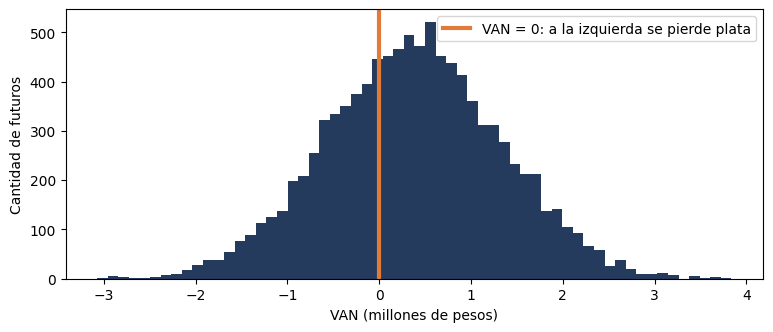

In [21]:
# Histograma de los 10.000 VAN: cuántos futuros cayeron en cada rango
vans.plot.hist(bins=60, color=AZUL, figsize=(9, 3.5))
plt.axvline(0, color=NARANJA, lw=3, label="VAN = 0: a la izquierda se pierde plata")   # línea en el cero
plt.xlabel("VAN (millones de pesos)")
plt.ylabel("Cantidad de futuros")
plt.legend()
plt.show()

En promedio el horno sigue conviniendo, pero en el **34,9%** de los futuros hace perder plata: más o menos **una chance en tres**.
Un número solo ("VAN = +0,38") esconde ese riesgo; la simulación lo muestra.

---
# 📝 Ejercicios

**Ejercicio 1 - Dos dados.** Tirá **dos dados** 100.000 veces (dos variables con `rng.integers`). ¿En qué porcentaje de las veces suman 7? Compará con la teoría: 6/36.

**Ejercicio 2 - Medialunas más caras.** Si hacer cada medialuna cuesta **\$350** (y se sigue vendiendo a \$500), ¿cuántas conviene hornear? ¿Más o menos que el promedio de 120? ¿Por qué?
*Pista: cambiá `COSTO` y volvé a correr el paso 3.*

**Ejercicio 3 - Un horno más incierto.** En el caso 2, ¿qué pasa con los futuros donde se pierde plata si los flujos varían un **30%** en vez de un 20%?

In [22]:
# Ejercicio 1 - tu respuesta acá

In [23]:
# Ejercicio 2 - tu respuesta acá

In [24]:
# Ejercicio 3 - tu respuesta acá

---
## Soluciones

Intentalo antes de mirar.

In [25]:
# Solución ejercicio 1
rng = np.random.default_rng(100)
dado1 = rng.integers(1, 7, size=100_000)     # 100.000 tiradas del primer dado
dado2 = rng.integers(1, 7, size=100_000)     # 100.000 tiradas del segundo dado

# (dado1 + dado2) == 7 es True cuando suman 7; .mean() da la proporción de True
print("Simulación:", round(((dado1 + dado2) == 7).mean() * 100, 1), "%")
print("Teoría    :", round(6 / 36 * 100, 1), "%")

Simulación: 16.7 %
Teoría    : 16.7 %


In [26]:
# Solución ejercicio 2
COSTO = 350        # cambiamos el costo; la función ganancia_promedio usa el valor nuevo

# Repetimos el paso 3: recalculamos la ganancia para cada cantidad y mostramos la mejor
resultados["ganancia promedio"] = resultados["hornear"].apply(ganancia_promedio)
print(resultados.sort_values("ganancia promedio", ascending=False).head(1))

# Conviene hornear MENOS que el promedio: ahora que sobre una cuesta $350,
# y quedarse sin una solo $150 (lo que se deja de ganar)
COSTO = 200        # volvemos al valor original

    hornear  ganancia promedio
22      112            15301.0


In [27]:
# Solución ejercicio 3: el mismo for del caso 2, pero con un desvío del 30%
rng = np.random.default_rng(101)
vans_30 = []
for i in range(10_000):
    flujos = rng.normal(flujos_esperados, 0.30 * flujos_esperados)   # 0.30 en vez de 0.20
    vans_30.append(calcular_van(flujos))

vans_30 = pd.Series(vans_30)
print("Futuros donde se pierde plata:", round((vans_30 < 0).mean() * 100, 1), "%")
# Más incertidumbre, más riesgo: el VAN promedio casi no cambia, pero se pierde plata más seguido.

Futuros donde se pierde plata: 39.5 %


---
# 🧭 Para llevarse

| Quiero... | En Python |
|---|---|
| números al azar que se puedan repetir | `rng = np.random.default_rng(42)` |
| elegir al azar entre opciones | `rng.choice(["A", "B"], size=..., p=[...])` |
| números de una campana (promedio y desvío) | `rng.normal(120, 15, size=1000)` |
| una muestra al azar | `df.sample(100, random_state=1)` |
| una muestra estratificada | `df.groupby("grupo").sample(frac=0.1, random_state=1)` |
| separar entrenamiento y prueba | `df.sample(frac=0.8, random_state=42)` y `df.drop(...)` |
| simular miles de futuros | un `for` que repite la cuenta y guarda cada resultado en una lista |

**Tres ideas:**
1. Más datos ayudan, pero cada vez menos: lo que más importa es **a quién** le preguntás.
2. **El sesgo no se arregla con más datos.**
3. Simular miles de futuros muestra el **riesgo** que un solo número esconde.

**En el TP:** digan siempre **de dónde salieron los datos** (¿toda la población o una muestra? ¿quién respondió?). Y si el análisis depende de supuestos inciertos, simulen escenarios en vez de mostrar un solo número.